In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

library(gridExtra)


install.packages("pROC")
library(pROC)
install.packages("pheatmap")

library(pheatmap)

install.packages("bubbleHeatmap")
library(bubbleHeatmap)

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


Updating HTML index of packages in '.Li

# Load and Merge Data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)

all_data <- merge(
  demo,
  ses_data,
  by = "person_id"
)

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data<-merge(merged_data, all_data, on="person_id", how="left")

dim(merged_data)

Rows: 135557 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adju...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 104508     78

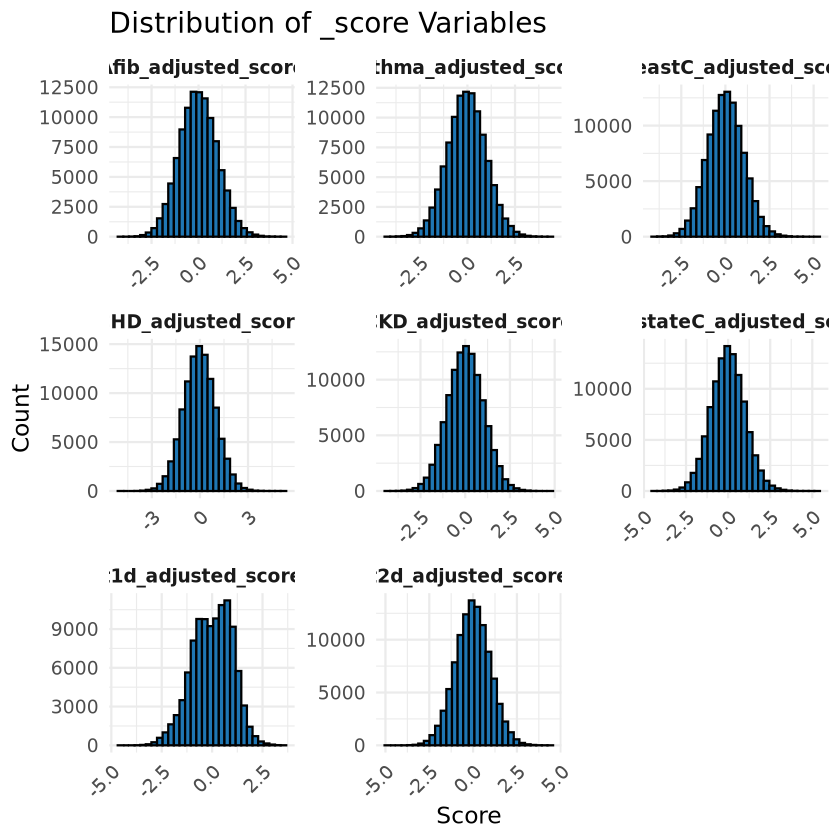

In [4]:
# Gather all _score columns into long format
merged_long <- merged_data %>%
  pivot_longer(
    cols = ends_with("_score"),
    names_to = "Score_Type",
    values_to = "Score_Value"
  )

# Plot faceted histograms
ggplot(merged_long, aes(x = Score_Value)) +
  geom_histogram(bins = 30, fill = "#1f77b4", color = "black") +
  facet_wrap(~ Score_Type, scales = "free") +
  theme_minimal(base_size = 14) +
  labs(
    x = "Score",
    y = "Count",
    title = "Distribution of _score Variables"
  ) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold")
  )


# Data Prep

In [5]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")
domains <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)

social_name_mapping <- c(
"individual_poverty" = "Individual Poverty",
  "education" = "Lower Individual Education", 
  "fraction_assisted_income" = "Assisted Income (%)",
  "fraction_no_high_school_education" = "No High School Education (%)",
  "lower_median_income" = "Lower Area Median Income",
  "fraction_no_health_insurance" = "No Health Insurance (%)",
  "fraction_poverty" = "Poverty (%)",
  "fraction_vacant_housing" = "Vacant Housing (%)",
  "deprivation_index" = "Area Deprivation Index"
)


disease_name_mapping <-c(
    "Asthma" = "Asthma", 
    "Afib" = "Afib",
    "BreastC" = "Breast Cancer",
    "CKD" = "CKD",
    "CHD" = "CHD",
    "ProstateC" = "Prostate Cancer",
    "t2d" = "T2D",
    "t1d" = "T1D"

)

In [6]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$age2 <- merged_data$age^2

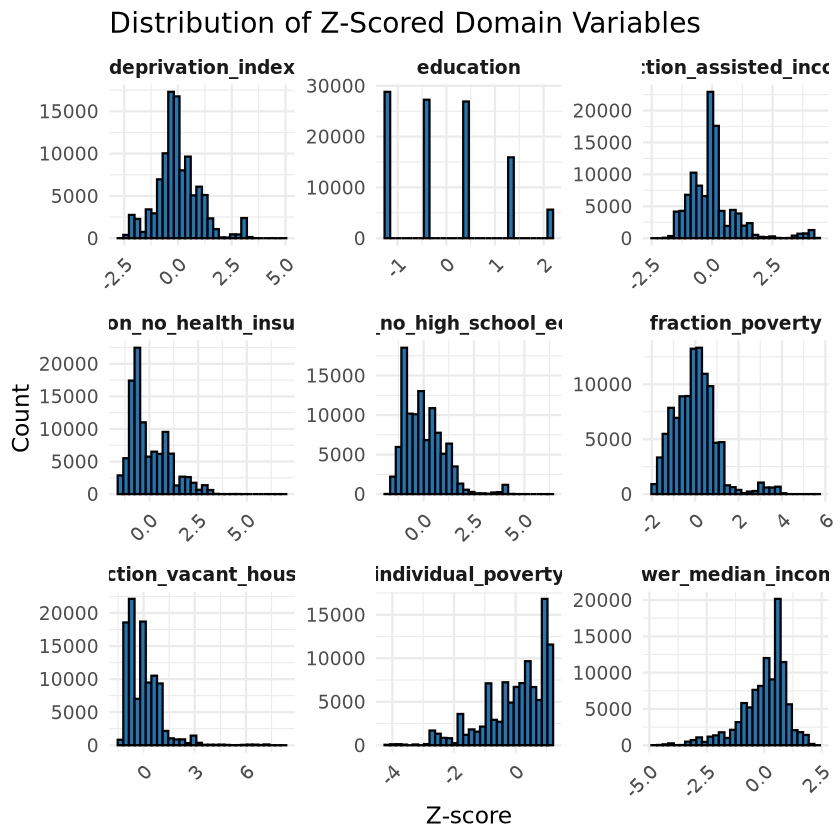

In [7]:
# Z-score normalize the domain columns
merged_z <- merged_data %>%
  mutate(across(all_of(domains), ~ (. - mean(., na.rm = TRUE)) / sd(., na.rm = TRUE)))

# Pivot to long format for plotting
merged_long <- merged_z %>%
  pivot_longer(
    cols = all_of(domains),
    names_to = "Score_Type",
    values_to = "Score_Value"
  )

# Plot faceted histograms
ggplot(merged_long, aes(x = Score_Value)) +
  geom_histogram(bins = 30, fill = "#1f77b4", color = "black") +
  facet_wrap(~ Score_Type, scales = "free") +
  theme_minimal(base_size = 14) +
  labs(
    x = "Z-score",
    y = "Count",
    title = "Distribution of Z-Scored Domain Variables"
  ) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold")
  )


# Regressions

## Models

In [28]:
generate_formulas <- function(disease, domain) {
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  if (disease %in% c("CKD", "t1d")) sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }

  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  prssocial <- paste0(score, ":", domain)
  f <- as.formula(paste(disease, "~", paste(c(base, score, domain, prssocial), collapse = " + ")))
  list(f)  # return a LIST
}

# accept either a formula OR a list of formulas
fit_and_extract <- function(formulas, disease, domain, data) {
  if (inherits(formulas, "formula")) formulas <- list(formulas)

  map_dfr(formulas, ~{
    filtered_data <- data
    if (disease %in% c("CKD", "t1d")) filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    if (disease == "BreastC")         filtered_data <- filtered_data %>% filter(SexGenderCis_female == 1)
    if (disease == "ProstateC")       filtered_data <- filtered_data %>% filter(SexGenderCis_male == 1)

    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    model <- suppressWarnings(glm(.x, data = filtered_data, family = binomial(link = "logit")))

    preds   <- predict(model, type = "response")
    actuals <- model$y
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)
      auc_val <- as.numeric(roc_obj$auc)
      auc_ci  <- as.numeric(ci.auc(roc_obj))
    } else {
      auc_val <- NA_real_; auc_ci <- c(NA_real_, NA_real_, NA_real_)
    }

    tidy_model <- tidy(model)

    if (nrow(tidy_model) > 0) {
      tidy_model <- tidy_model %>%
        mutate(
          estimate_CI_lower = estimate - 1.96 * std.error,
          estimate_CI_upper = estimate + 1.96 * std.error
        )
    } else {
      # Create empty columns if tidy_model has no rows
      tidy_model <- tibble(
        term = character(0),
        estimate = numeric(0),
        std.error = numeric(0),
        statistic = numeric(0),
        p.value = numeric(0),
        estimate_CI_lower = numeric(0),
        estimate_CI_upper = numeric(0)
      )
    }

    tidy_model %>%
      mutate(
        Disease       = disease,
        Domain        = domain,
        Model_Formula = paste(deparse(.x), collapse = " "),
        AUC           = auc_val,
        AUC_CI_Lower  = auc_ci[1],
        AUC_CI_Upper  = auc_ci[3]
      )
  })
}

# combos
combinations <- expand_grid(
  disease = unlist(diseases),
  domain  = domains
)

#Get results
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, merged_z))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value, estimate_CI_lower, estimate_CI_upper,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)


# Main Plot A

In [9]:
########################### Interaction Effect #############################

auc_plot_data <- results %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, estimate, std.error, statistic, p.value, estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()


auc_plot_data_interaction <- auc_plot_data |>
    rename(est.int = estimate,
          std.error.int = std.error,
          statistic.int = statistic,
          p.value.int =  p.value) |>
    select(-c(estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper))

########################### Main PRS Effect #############################

auc_plot_data_main <- results %>%
  filter(grepl("_score$", term)) %>%   # keep rows where Domain contains "_score"
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value
  ) %>%
  distinct()

auc_plot_data_main <- auc_plot_data_main |>
    rename(est.PRS = estimate,
          std.error.PRS = std.error,
          statistic.PRS = statistic,
          p.value.PRS =  p.value)

########################### Main SDoH Effect #############################

auc_plot_data_sdoh <- results %>%
  filter(term %in% domains) %>%   
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value,  AUC, AUC_CI_Lower, AUC_CI_Upper
  ) %>%
  distinct()

auc_plot_data_sdoh <- auc_plot_data_sdoh |>
    rename(est.SDoH = estimate,
          std.error.SDoH = std.error,
          statistic.SDoH = statistic,
          p.value.SDoH =  p.value)


#Combine 
merged_data <- auc_plot_data_interaction %>%
  left_join(auc_plot_data_main, by = c("Disease", "Domain"))

merged_data <- merged_data %>%
  left_join(auc_plot_data_sdoh, by = c("Disease", "Domain"))


merged_data$Domain <- social_name_mapping[merged_data$Domain]
merged_data$Disease <- disease_name_mapping[merged_data$Disease]

merged_data <- merged_data %>%
  distinct()

#Save table
write_excel_csv(merged_data, file.path(output_dir, "Interaction_statistic.csv"))


In [10]:
auc_plot_data$Domain <- social_name_mapping[auc_plot_data$Domain]
auc_plot_data$Disease <- disease_name_mapping[auc_plot_data$Disease]



# Define column order for heatmap

y_axis_order <- c('Lower Individual Education', 'Individual Poverty','Assisted Income (%)',
           'No High School Education (%)', "Lower Area Median Income",
           'No Health Insurance (%)', 'Poverty (%)', 'Vacant Housing (%)', 'Area Deprivation Index')


x_axis_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D", "CKD", "CHD", "Asthma", "T1D")

# Bonferroni threshold
alpha <- 0.05
alpha_bonf <- alpha / (length(unique(results$Disease)) * length(unique(results$Domain)))

auc_plot_data <- auc_plot_data %>%
  mutate(
    Disease  = factor(Disease, levels = x_axis_order),
    Domain = factor(Domain, levels = y_axis_order)
  ) 

colorMat <- auc_plot_data %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Disease, values_from = estimate) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

sizeMat <- auc_plot_data %>%
  mutate(size_val = -log10(p.value)) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

colorMat <- colorMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

colorMat <- as.matrix(colorMat)

sizeMat <- sizeMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

sizeMat <- as.matrix(sizeMat)


max_val <- max(abs(colorMat), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


In [11]:
tree <- bubbleHeatmap(
  colorMat,
  sizeMat,
  treeName = "",

  plotTitle = "",
  xTitle    = "",
  yTitle    = "",
    
  
  colorLim = c(-.14, .14),

  legendTitles = c(
    expression(-log[10](p)),
      "Effect Size"
  ),
        
  colorSeq = color_palette
)

Warning message:
“
bubbleHeatmap must be drawn on a graphics device with gradient
            fill support (e.g. cairo_pdf or png(type = 'cairo')) in order to
            render the color legend correctly.

            This warning will be shown  once per session and may be disabled
            by setting options('bubbleLegends.device.warning' = FALSE)”


In [ ]:

options(repr.plot.width = 6, repr.plot.height = 12)  # Set width and height

grid.newpage()
grid.draw(tree)

In [13]:
auc_plot_data %>%
  mutate(
    bonf_thresh = 0.05 / (n_distinct(Disease) * n_distinct(Domain)),
    size_val = ifelse(p.value > bonf_thresh, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0.0000000000,0,0,2.914819e-10,5.854123e-04,0,3.738932e-14,0.00030332
Lower Individual Education,0.0001841636,0,0,5.651243e-05,3.669914e-04,0,7.650079e-09,0.00000000
Assisted Income (%),0.0000000000,0,0,4.172384e-05,7.759512e-08,0,1.184787e-09,0.00000000
No High School Education (%),0.0000000000,0,0,0.000000e+00,3.358768e-04,0,2.290400e-04,0.00000000
Lower Area Median Income,0.0000000000,0,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0.00000000
No Health Insurance (%),0.0000000000,0,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0.00000000
Poverty (%),0.0000000000,0,0,2.580682e-08,1.695879e-06,0,3.160382e-07,0.00000000
Vacant Housing (%),0.0000000000,0,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0.00000000
Area Deprivation Index,0.0000000000,0,0,4.241823e-06,6.726913e-05,0,1.351453e-06,0.00000000


In [14]:
auc_plot_data %>%
  mutate(
    size_val = ifelse(p.adjust(p.value, method = "BH") > 0.05, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0.0032598055,0,0,2.914819e-10,5.854123e-04,0,3.738932e-14,0.00030332
Lower Individual Education,0.0001841636,0,0,5.651243e-05,3.669914e-04,0,7.650079e-09,0.00000000
Assisted Income (%),0.0000000000,0,0,4.172384e-05,7.759512e-08,0,1.184787e-09,0.00000000
No High School Education (%),0.0000000000,0,0,1.026578e-03,3.358768e-04,0,2.290400e-04,0.00000000
Lower Area Median Income,0.0000000000,0,0,3.302852e-03,0.000000e+00,0,1.007744e-03,0.00000000
No Health Insurance (%),0.0000000000,0,0,7.755200e-04,0.000000e+00,0,0.000000e+00,0.00000000
Poverty (%),0.0000000000,0,0,2.580682e-08,1.695879e-06,0,3.160382e-07,0.00000000
Vacant Housing (%),0.0000000000,0,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0.00000000
Area Deprivation Index,0.0000000000,0,0,4.241823e-06,6.726913e-05,0,1.351453e-06,0.00000000


# Controlling for PCs

In [15]:
generate_formulas_PCs <- function(disease, domain) {
  covariates <- c("age", "age2", "record_depth", "visit_frequency", paste0("PC_",1:16))
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  if (disease %in% c("CKD", "t1d")) sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }


  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")
  prssocial <- paste0(score, ":", domain)
  f <- as.formula(paste(disease, "~", paste(c(base, score, domain, prssocial), collapse = " + ")))
  list(f)  # return a LIST
}

# combos
combinations <- expand_grid(
  disease = unlist(diseases),
  domain  = domains
)

#Get results
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas_PCs(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, merged_z))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)


In [16]:
auc_plot_data <- results %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()


In [17]:
########################### Interaction Effect #############################

auc_plot_data_interaction <- auc_plot_data |>
    rename(est.int = estimate,
          std.error.int = std.error,
          statistic.int = statistic,
          p.value.int =  p.value) |>
    select(-c(AUC, AUC_CI_Lower, AUC_CI_Upper))


########################### Main PRS Effect #############################

auc_plot_data_main <- results %>%
  filter(grepl("_score$", term)) %>%   # keep rows where Domain contains "_score"
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value
  ) %>%
  distinct()

auc_plot_data_main <- auc_plot_data_main |>
    rename(est.PRS = estimate,
          std.error.PRS = std.error,
          statistic.PRS = statistic,
          p.value.PRS =  p.value)

########################### Main SDoH Effect #############################

auc_plot_data_sdoh <- results %>%
  filter(term %in% domains) %>%   
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value,  AUC, AUC_CI_Lower, AUC_CI_Upper
  ) %>%
  distinct()

auc_plot_data_sdoh <- auc_plot_data_sdoh |>
    rename(est.SDoH = estimate,
          std.error.SDoH = std.error,
          statistic.SDoH = statistic,
          p.value.SDoH =  p.value)


#Combine 
merged_data <- auc_plot_data_interaction %>%
  left_join(auc_plot_data_main, by = c("Disease", "Domain"))

merged_data <- merged_data %>%
  left_join(auc_plot_data_sdoh, by = c("Disease", "Domain"))


merged_data$Domain <- social_name_mapping[merged_data$Domain]
merged_data$Disease <- disease_name_mapping[merged_data$Disease]

merged_data <- merged_data %>%
  distinct()

#Save table
write_excel_csv(merged_data, file.path(output_dir, "Interaction_statistic_PC.csv"))

In [18]:
auc_plot_data$Domain <- social_name_mapping[auc_plot_data$Domain]
auc_plot_data$Disease <- disease_name_mapping[auc_plot_data$Disease]


# Bonferroni threshold
alpha <- 0.05
alpha_bonf <- alpha / (length(unique(results$Disease)) * length(unique(results$Domain)))

auc_plot_data <- auc_plot_data %>%
  mutate(
    Disease  = factor(Disease, levels = x_axis_order),
    Domain = factor(Domain, levels = y_axis_order)
  ) 

colorMat <- auc_plot_data %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Disease, values_from = estimate) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

sizeMat <- auc_plot_data %>%
  mutate(size_val = -log10(p.value)) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

colorMat <- colorMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

colorMat <- as.matrix(colorMat)

sizeMat <- sizeMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

sizeMat <- as.matrix(sizeMat)


max_val <- max(abs(colorMat), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors

tree <- bubbleHeatmap(
  colorMat,
  sizeMat,
  treeName = "",

  plotTitle = "",
  xTitle    = "",
  yTitle    = "",
    
  
  colorLim = c(-.14, .14),

  legendTitles = c(
    expression(-log[10](p)),
      "Effect Size"
  ),
        
  colorSeq = color_palette
)



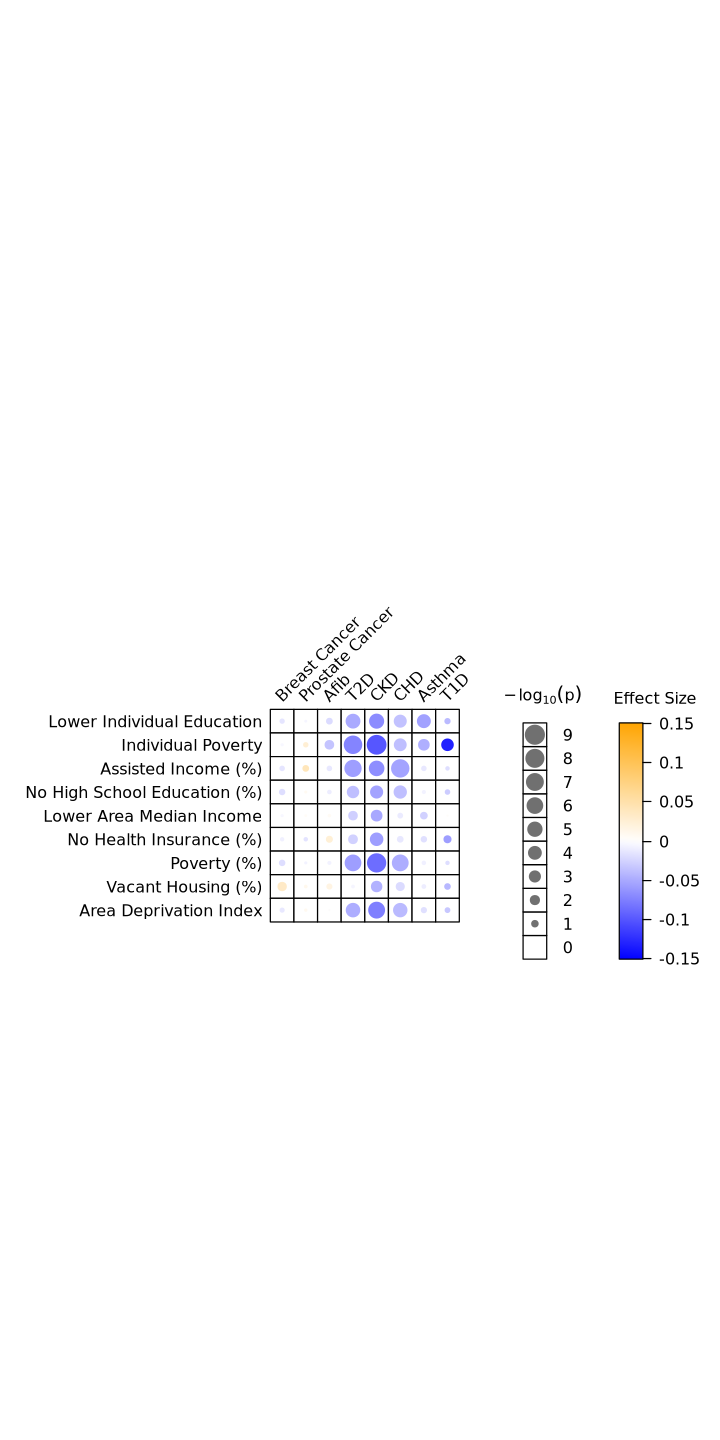

In [19]:
options(repr.plot.width = 6, repr.plot.height = 12)  # Set width and height

grid.newpage()
grid.draw(tree)

In [20]:
auc_plot_data %>%
  mutate(
    bonf_thresh = 0.05 / (n_distinct(Disease) * n_distinct(Domain)),
    size_val = ifelse(p.value > bonf_thresh, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0.000000e+00,0,0,2.035363e-09,3.871707e-04,0,2.966012e-08,0.0005548283
Lower Individual Education,8.296638e-05,0,0,1.397156e-05,3.041870e-04,0,2.199806e-05,0.0000000000
Assisted Income (%),0.000000e+00,0,0,6.386305e-06,3.881296e-08,0,3.212842e-07,0.0000000000
No High School Education (%),0.000000e+00,0,0,2.761291e-04,2.029986e-04,0,6.936413e-04,0.0000000000
Lower Area Median Income,0.000000e+00,0,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0.0000000000
No Health Insurance (%),0.000000e+00,0,0,1.548880e-04,0.000000e+00,0,0.000000e+00,0.0000000000
Poverty (%),0.000000e+00,0,0,6.324486e-09,7.447002e-07,0,8.758036e-07,0.0000000000
Vacant Housing (%),0.000000e+00,0,0,0.000000e+00,0.000000e+00,0,0.000000e+00,0.0000000000
Area Deprivation Index,0.000000e+00,0,0,6.417952e-07,3.997782e-05,0,3.419144e-05,0.0000000000


# Unadjusted PRS

In [21]:
# Define conditions and readable disease names
conditions <- c(
  "asthma",
  "atrial_fibrilation",
  "breast_cancer",
  "ckd",
  "coronary_heart_disease",
  "hypercholesterolemia",
  "prostate_cancer",
  "t1d",
  "t2d"
)

disease_labels <- c(
  "Asthma",
  "Afib",
  "BreastC",
  "CKD",
  "CHD",
  "HyperC",
  "ProstateC",
  "t1d",
  "t2d"
)


all_prs <- NULL


# Loop through all conditions
for (i in seq_along(conditions)) {
  condition <- conditions[i]
  disease <- disease_labels[i]
  
  # Define filename
  name_of_file_in_bucket <- paste0(current_directory, "/data/combined_", condition, ".txt")
  
  # Read CSV
  prs <- read_csv(name_of_file_in_bucket, show_col_types = FALSE) |> select(1,4)
  
  # Add disease label and rename the score column
  prs <- prs %>%
  rename(!!paste0(disease, "_score") := 2) %>%
  rename("person_id" := 1)
  
  # Merge by IID
  if (is.null(all_prs)) {
    all_prs <- prs
  } else {
    all_prs <- merge(all_prs, prs, by = "person_id")
  }
}


#MERGE
merged_data<-merge(merged_z, all_prs, on="person_id", how="inner")

merged_data <- merged_data %>%
  mutate(across(ends_with("_score"),
                ~ (.-min(., na.rm = TRUE)) /
                  (max(., na.rm = TRUE) - min(., na.rm = TRUE))
                ))



In [22]:
generate_formulas_unj_PRS <- function(disease, domain) {
  covariates <- c("age", "age2", "record_depth", "visit_frequency", paste0("PC_",1:16))
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  if (disease %in% c("CKD", "t1d")) sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  if (disease %in% c("BreastC", "ProstateC")) { sex_terms <- character(0) }


  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_score")
  prssocial <- paste0(score, ":", domain)
  f <- as.formula(paste(disease, "~", paste(c(base, score, domain, prssocial), collapse = " + ")))
  list(f)  # return a LIST
}

# combos
combinations <- expand_grid(
  disease = unlist(diseases),
  domain  = domains
)

#Get results
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas_unj_PRS(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, merged_data))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)


In [23]:
auc_plot_data <- results %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()



########################### Interaction Effect #############################

auc_plot_data_interaction <- auc_plot_data |>
    rename(est.int = estimate,
          std.error.int = std.error,
          statistic.int = statistic,
          p.value.int =  p.value) |>
    select(-c(AUC, AUC_CI_Lower, AUC_CI_Upper))


########################### Main PRS Effect #############################

auc_plot_data_main <- results %>%
  filter(grepl("_score$", term)) %>%   # keep rows where Domain contains "_score"
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value
  ) %>%
  distinct()

auc_plot_data_main <- auc_plot_data_main |>
    rename(est.PRS = estimate,
          std.error.PRS = std.error,
          statistic.PRS = statistic,
          p.value.PRS =  p.value)

########################### Main SDoH Effect #############################

auc_plot_data_sdoh <- results %>%
  filter(term %in% domains) %>%   
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value,  AUC, AUC_CI_Lower, AUC_CI_Upper
  ) %>%
  distinct()

auc_plot_data_sdoh <- auc_plot_data_sdoh |>
    rename(est.SDoH = estimate,
          std.error.SDoH = std.error,
          statistic.SDoH = statistic,
          p.value.SDoH =  p.value)


#Combine 
merged_data <- auc_plot_data_interaction %>%
  left_join(auc_plot_data_main, by = c("Disease", "Domain"))

merged_data <- merged_data %>%
  left_join(auc_plot_data_sdoh, by = c("Disease", "Domain"))


merged_data$Domain <- social_name_mapping[merged_data$Domain]
merged_data$Disease <- disease_name_mapping[merged_data$Disease]

merged_data <- merged_data %>%
  distinct()

#Save table
write_excel_csv(merged_data, file.path(output_dir, "Interaction_statistic_non_adj_PRS.csv"))


auc_plot_data$Domain <- social_name_mapping[auc_plot_data$Domain]
auc_plot_data$Disease <- disease_name_mapping[auc_plot_data$Disease]



# Bonferroni threshold
alpha <- 0.05
alpha_bonf <- alpha / (length(unique(results$Disease)) * length(unique(results$Domain)))

auc_plot_data <- auc_plot_data %>%
  mutate(
    Disease  = factor(Disease, levels = x_axis_order),
    Domain = factor(Domain, levels = y_axis_order)
  ) 

colorMat <- auc_plot_data %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Disease, values_from = estimate) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

sizeMat <- auc_plot_data %>%
  mutate(size_val = -log10(p.value)) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

colorMat <- colorMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

colorMat <- as.matrix(colorMat)

sizeMat <- sizeMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

sizeMat <- as.matrix(sizeMat)


max_val <- max(abs(colorMat), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors

tree <- bubbleHeatmap(
  colorMat,
  sizeMat,
  treeName = "",

  plotTitle = "",
  xTitle    = "",
  yTitle    = "",
    
  
  colorLim = c(-2, 2),

  legendTitles = c(
    expression(-log[10](p)),
      "Effect Size"
  ),
        
  colorSeq = color_palette
)


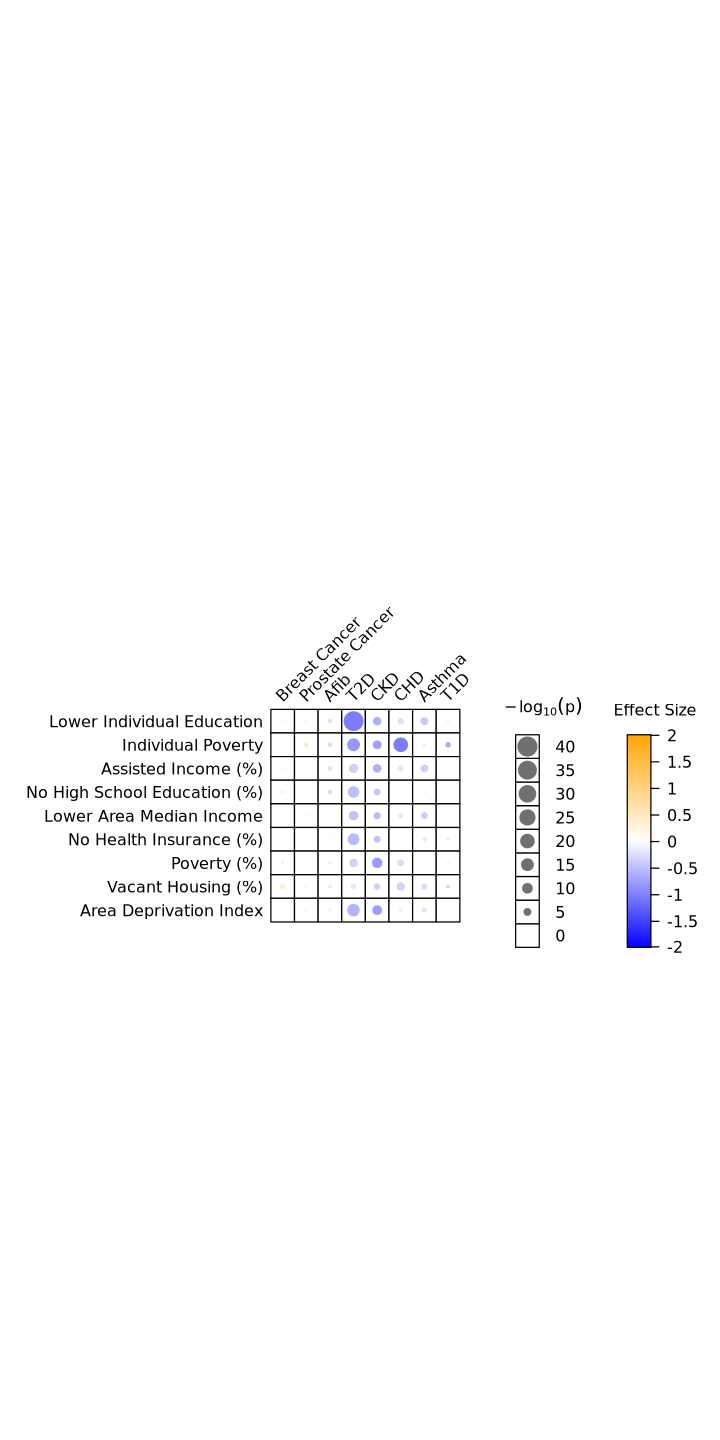

In [24]:
options(repr.plot.width = 6, repr.plot.height = 12)  # Set width and height

grid.newpage()
grid.draw(tree)

In [25]:
auc_plot_data %>%
  mutate(
    bonf_thresh = 0.05 / (n_distinct(Disease) * n_distinct(Domain)),
    size_val = ifelse(p.value > bonf_thresh, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0.000000e+00,0,0,2.862455e-07,6.571022e-21,0,9.047661e-16,0
Lower Individual Education,1.093572e-05,0,0,2.087920e-06,0.000000e+00,0,8.931533e-40,0
Assisted Income (%),1.972764e-05,0,0,8.456399e-07,0.000000e+00,0,1.017539e-07,0
No High School Education (%),0.000000e+00,0,0,4.311649e-04,0.000000e+00,0,1.787210e-12,0
Lower Area Median Income,3.396267e-04,0,0,1.067984e-04,0.000000e+00,0,2.664671e-08,0
No Health Insurance (%),0.000000e+00,0,0,2.569653e-04,0.000000e+00,0,7.049168e-13,0
Poverty (%),0.000000e+00,0,0,5.831491e-10,2.486328e-04,0,1.229927e-06,0
Vacant Housing (%),0.000000e+00,0,0,0.000000e+00,4.018558e-06,0,0.000000e+00,0
Area Deprivation Index,0.000000e+00,0,0,7.145504e-09,0.000000e+00,0,5.844294e-15,0


# Ancestry stratified

## EUR

In [51]:
eur <- merged_z[merged_z$ancestry_pred == "eur",]

#Get results
results_eur <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, eur))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value, estimate_CI_lower, estimate_CI_upper,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)

########################### Interaction Effect #############################

auc_plot_data <- results_eur %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, estimate, std.error, statistic, p.value, estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()


auc_plot_data_interaction <- auc_plot_data |>
    rename(est.int = estimate,
          std.error.int = std.error,
          statistic.int = statistic,
          p.value.int =  p.value) |>
    select(-c(estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper))

########################### Main PRS Effect #############################

auc_plot_data_main <- results_eur %>%
  filter(grepl("_score$", term)) %>%   # keep rows where Domain contains "_score"
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value
  ) %>%
  distinct()

auc_plot_data_main <- auc_plot_data_main |>
    rename(est.PRS = estimate,
          std.error.PRS = std.error,
          statistic.PRS = statistic,
          p.value.PRS =  p.value)

########################### Main SDoH Effect #############################

auc_plot_data_sdoh <- results_eur %>%
  filter(term %in% domains) %>%   
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value,  AUC, AUC_CI_Lower, AUC_CI_Upper
  ) %>%
  distinct()

auc_plot_data_sdoh <- auc_plot_data_sdoh |>
    rename(est.SDoH = estimate,
          std.error.SDoH = std.error,
          statistic.SDoH = statistic,
          p.value.SDoH =  p.value)


#Combine 
merged_data <- auc_plot_data_interaction %>%
  left_join(auc_plot_data_main, by = c("Disease", "Domain"))

merged_data <- merged_data %>%
  left_join(auc_plot_data_sdoh, by = c("Disease", "Domain"))


merged_data$Domain <- social_name_mapping[merged_data$Domain]
merged_data$Disease <- disease_name_mapping[merged_data$Disease]

merged_data_eur <- merged_data %>%
  distinct()


In [52]:
auc_plot_data$Domain <- social_name_mapping[auc_plot_data$Domain]
auc_plot_data$Disease <- disease_name_mapping[auc_plot_data$Disease]



# Define column order for heatmap

y_axis_order <- c('Lower Individual Education', 'Individual Poverty','Assisted Income (%)',
           'No High School Education (%)', "Lower Area Median Income",
           'No Health Insurance (%)', 'Poverty (%)', 'Vacant Housing (%)', 'Area Deprivation Index')


x_axis_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D", "CKD", "CHD", "Asthma", "T1D")

# Bonferroni threshold
alpha <- 0.05
alpha_bonf <- alpha / (length(unique(results$Disease)) * length(unique(results$Domain)))

auc_plot_data <- auc_plot_data %>%
  mutate(
    Disease  = factor(Disease, levels = x_axis_order),
    Domain = factor(Domain, levels = y_axis_order)
  ) 

colorMat <- auc_plot_data %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Disease, values_from = estimate) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

sizeMat <- auc_plot_data %>%
  mutate(size_val = -log10(p.value)) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

colorMat <- colorMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

colorMat <- as.matrix(colorMat)

sizeMat <- sizeMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

sizeMat <- as.matrix(sizeMat)


max_val <- max(abs(colorMat), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


In [53]:
tree <- bubbleHeatmap(
  colorMat,
  sizeMat,
  treeName = "",

  plotTitle = "",
  xTitle    = "",
  yTitle    = "",
    
  
  colorLim = c(-.14, .14),

  legendTitles = c(
    expression(-log[10](p)),
      "Effect Size"
  ),
        
  colorSeq = color_palette
)

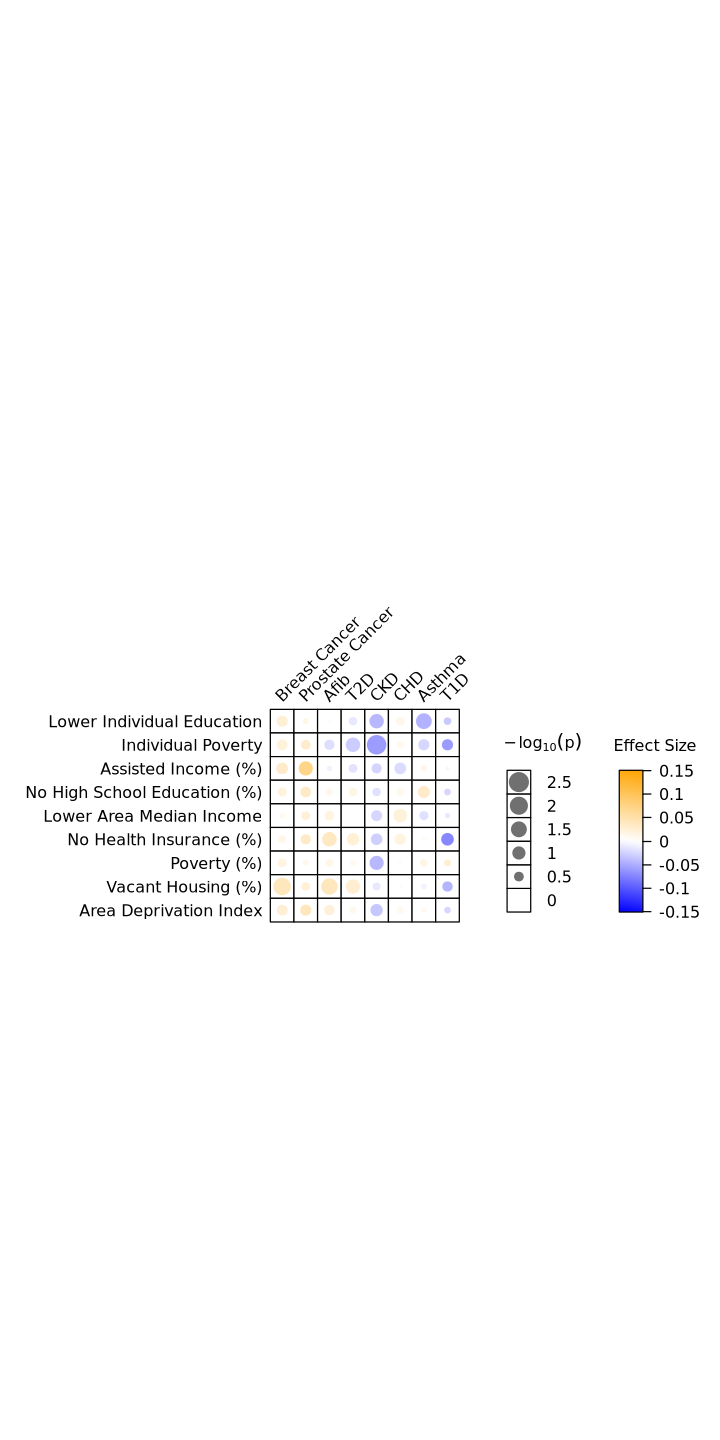

In [54]:
options(repr.plot.width = 6, repr.plot.height = 12)  # Set width and height

grid.newpage()
grid.draw(tree)

In [44]:
auc_plot_data %>%
  mutate(
    bonf_thresh = 0.05 / (n_distinct(Disease) * n_distinct(Domain)),
    size_val = ifelse(p.value > bonf_thresh, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

auc_plot_data %>%
  mutate(
    size_val = ifelse(p.adjust(p.value, method = "BH") > 0.05, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0,0,0,0,0,0,0,0
Lower Individual Education,0,0,0,0,0,0,0,0
Assisted Income (%),0,0,0,0,0,0,0,0
No High School Education (%),0,0,0,0,0,0,0,0
Lower Area Median Income,0,0,0,0,0,0,0,0
No Health Insurance (%),0,0,0,0,0,0,0,0
Poverty (%),0,0,0,0,0,0,0,0
Vacant Housing (%),0,0,0,0,0,0,0,0
Area Deprivation Index,0,0,0,0,0,0,0,0


,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0,0,0,0,0,0,0,0
Lower Individual Education,0,0,0,0,0,0,0,0
Assisted Income (%),0,0,0,0,0,0,0,0
No High School Education (%),0,0,0,0,0,0,0,0
Lower Area Median Income,0,0,0,0,0,0,0,0
No Health Insurance (%),0,0,0,0,0,0,0,0
Poverty (%),0,0,0,0,0,0,0,0
Vacant Housing (%),0,0,0,0,0,0,0,0
Area Deprivation Index,0,0,0,0,0,0,0,0


## AFR

In [45]:
afr <- merged_z[merged_z$ancestry_pred == "afr",]

#Get results
results_afr <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, afr))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value, estimate_CI_lower, estimate_CI_upper,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)

########################### Interaction Effect #############################

auc_plot_data <- results_afr %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, estimate, std.error, statistic, p.value, estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()


auc_plot_data_interaction <- auc_plot_data |>
    rename(est.int = estimate,
          std.error.int = std.error,
          statistic.int = statistic,
          p.value.int =  p.value) |>
    select(-c(estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper))

########################### Main PRS Effect #############################

auc_plot_data_main <- results_afr %>%
  filter(grepl("_score$", term)) %>%   # keep rows where Domain contains "_score"
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value
  ) %>%
  distinct()

auc_plot_data_main <- auc_plot_data_main |>
    rename(est.PRS = estimate,
          std.error.PRS = std.error,
          statistic.PRS = statistic,
          p.value.PRS =  p.value)

########################### Main SDoH Effect #############################

auc_plot_data_sdoh <- results_afr %>%
  filter(term %in% domains) %>%   
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value,  AUC, AUC_CI_Lower, AUC_CI_Upper
  ) %>%
  distinct()

auc_plot_data_sdoh <- auc_plot_data_sdoh |>
    rename(est.SDoH = estimate,
          std.error.SDoH = std.error,
          statistic.SDoH = statistic,
          p.value.SDoH =  p.value)


#Combine 
merged_data <- auc_plot_data_interaction %>%
  left_join(auc_plot_data_main, by = c("Disease", "Domain"))

merged_data <- merged_data %>%
  left_join(auc_plot_data_sdoh, by = c("Disease", "Domain"))


merged_data$Domain <- social_name_mapping[merged_data$Domain]
merged_data$Disease <- disease_name_mapping[merged_data$Disease]

merged_data_afr <- merged_data %>%
  distinct()

merged_data_afr$Ancestry <- "AFR"
merged_data_eur$Ancestry <- "EUR"

merged_data <- rbind(merged_data_afr, merged_data_eur)

write_excel_csv(merged_data, file.path(output_dir, "Interaction_statistic_ancestry_stratified.csv"))


In [46]:
auc_plot_data$Domain <- social_name_mapping[auc_plot_data$Domain]
auc_plot_data$Disease <- disease_name_mapping[auc_plot_data$Disease]



# Define column order for heatmap

y_axis_order <- c('Lower Individual Education', 'Individual Poverty','Assisted Income (%)',
           'No High School Education (%)', "Lower Area Median Income",
           'No Health Insurance (%)', 'Poverty (%)', 'Vacant Housing (%)', 'Area Deprivation Index')


x_axis_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D", "CKD", "CHD", "Asthma", "T1D")

# Bonferroni threshold
alpha <- 0.05
alpha_bonf <- alpha / (length(unique(results$Disease)) * length(unique(results$Domain)))

auc_plot_data <- auc_plot_data %>%
  mutate(
    Disease  = factor(Disease, levels = x_axis_order),
    Domain = factor(Domain, levels = y_axis_order)
  ) 

colorMat <- auc_plot_data %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Disease, values_from = estimate) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

sizeMat <- auc_plot_data %>%
  mutate(size_val = -log10(p.value)) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

colorMat <- colorMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

colorMat <- as.matrix(colorMat)

sizeMat <- sizeMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

sizeMat <- as.matrix(sizeMat)


max_val <- max(abs(colorMat), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


In [47]:
tree <- bubbleHeatmap(
  colorMat,
  sizeMat,
  treeName = "",

  plotTitle = "",
  xTitle    = "",
  yTitle    = "",
    
  
  colorLim = c(-.14, .14),

  legendTitles = c(
    expression(-log[10](p)),
      "Effect Size"
  ),
        
  colorSeq = color_palette
)

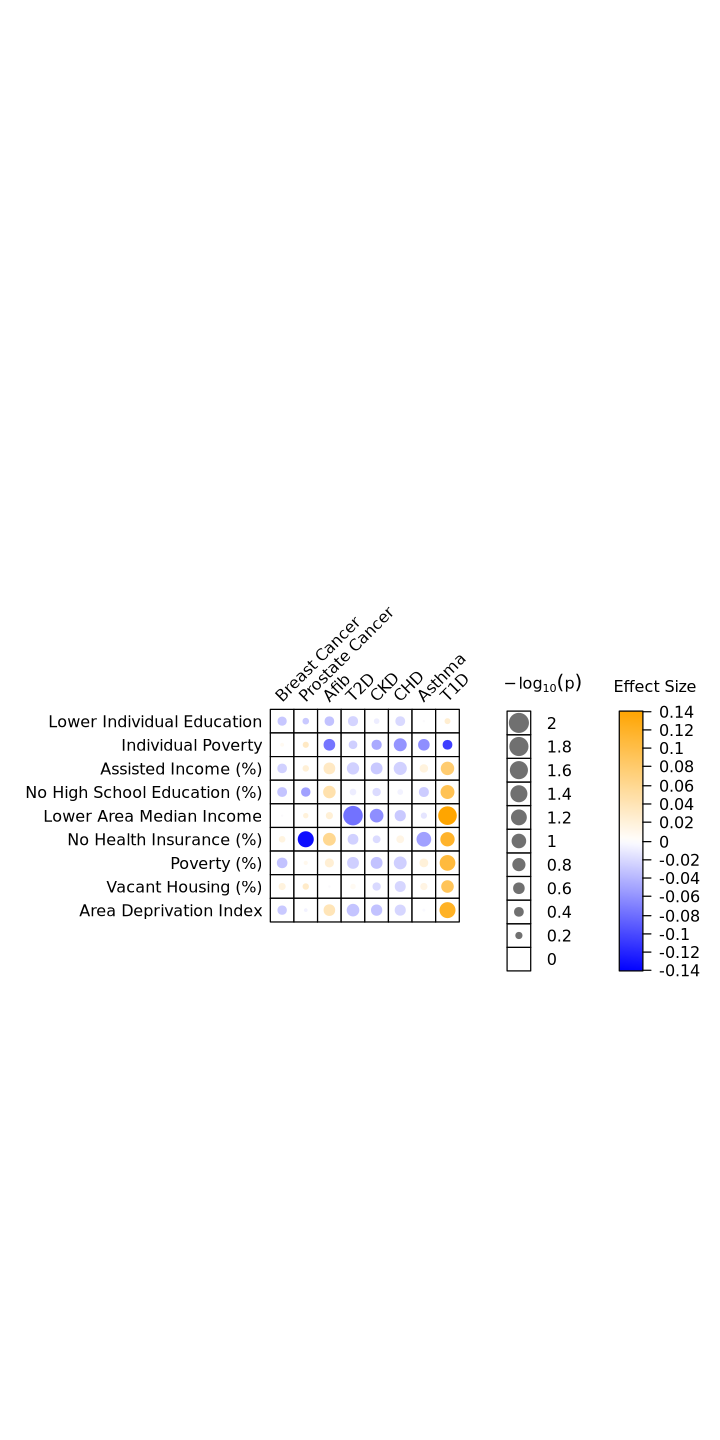

In [48]:
options(repr.plot.width = 6, repr.plot.height = 12)  # Set width and height

grid.newpage()
grid.draw(tree)

In [49]:
auc_plot_data %>%
  mutate(
    bonf_thresh = 0.05 / (n_distinct(Disease) * n_distinct(Domain)),
    size_val = ifelse(p.value > bonf_thresh, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

auc_plot_data %>%
  mutate(
    size_val = ifelse(p.adjust(p.value, method = "BH") > 0.05, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0,0,0,0,0,0,0,0
Lower Individual Education,0,0,0,0,0,0,0,0
Assisted Income (%),0,0,0,0,0,0,0,0
No High School Education (%),0,0,0,0,0,0,0,0
Lower Area Median Income,0,0,0,0,0,0,0,0
No Health Insurance (%),0,0,0,0,0,0,0,0
Poverty (%),0,0,0,0,0,0,0,0
Vacant Housing (%),0,0,0,0,0,0,0,0
Area Deprivation Index,0,0,0,0,0,0,0,0


,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0,0,0,0,0,0,0,0
Lower Individual Education,0,0,0,0,0,0,0,0
Assisted Income (%),0,0,0,0,0,0,0,0
No High School Education (%),0,0,0,0,0,0,0,0
Lower Area Median Income,0,0,0,0,0,0,0,0
No Health Insurance (%),0,0,0,0,0,0,0,0
Poverty (%),0,0,0,0,0,0,0,0
Vacant Housing (%),0,0,0,0,0,0,0,0
Area Deprivation Index,0,0,0,0,0,0,0,0


# Random Downsample

In [50]:
afr_counts <- data.frame(
  disease = diseases,
  cases = sapply(diseases, function(disease) sum(afr[[disease]] == 1, na.rm = TRUE)),
  controls = sapply(diseases, function(disease) sum(afr[[disease]] == 0, na.rm = TRUE))
)

afr_counts

data.frame(
  disease = diseases,
  cases = sapply(diseases, function(disease) sum(eur[[disease]] == 1, na.rm = TRUE)),
  controls = sapply(diseases, function(disease) sum(eur[[disease]] == 0, na.rm = TRUE))
)

                 
downsampled_merged <- lapply(diseases, function(disease) {
  n_cases <- afr_counts$cases[afr_counts$disease == disease]
  n_controls <- afr_counts$controls[afr_counts$disease == disease]

  cases_df <- merged_data[merged_data[[disease]] == 1 & !is.na(merged_data[[disease]]), ]
  controls_df <- merged_data[merged_data[[disease]] == 0 & !is.na(merged_data[[disease]]), ]

  data.frame(
    rbind(
      cases_df[sample(nrow(cases_df), min(n_cases, nrow(cases_df))), ],
      controls_df[sample(nrow(controls_df), min(n_controls, nrow(controls_df))), ]
    ),
    matched_disease = disease
  )
})

downsampled_merged <- do.call(rbind, downsampled_merged)


,disease,cases,controls
,<chr>,<int>,<int>
Asthma,Asthma,2613,3849
Afib,Afib,887,4050
BreastC,BreastC,702,12396
CKD,CKD,2386,4637
CHD,CHD,2506,15742
ProstateC,ProstateC,451,601
t2d,t2d,4715,4282
t1d,t1d,219,4282


,disease,cases,controls
,<chr>,<int>,<int>
Asthma,Asthma,7983,11137
Afib,Afib,6883,11457
BreastC,BreastC,4141,39343
CKD,CKD,6097,20927
CHD,CHD,11047,58100
ProstateC,ProstateC,2962,5118
t2d,t2d,10530,27176
t1d,t1d,751,27176


In [55]:
#Get results
results_downsampled <- combinations %>%
  rowwise() %>%
  mutate(
    formulas      = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, afr))
  ) %>%
  ungroup() %>%
  select(-formulas) %>%
  unnest(model_results) %>%
  select(Disease, Domain, term, estimate, std.error, statistic, p.value, estimate_CI_lower, estimate_CI_upper,
         AUC, AUC_CI_Lower, AUC_CI_Upper, Model_Formula)

########################### Interaction Effect #############################

auc_plot_data <- results_downsampled %>%
  filter(str_detect(term, ":")) %>%  # Keep terms that include an interaction
  filter(!is.na(AUC)) %>%
  select(Disease, Domain, estimate, std.error, statistic, p.value, estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()


auc_plot_data_interaction <- auc_plot_data |>
    rename(est.int = estimate,
          std.error.int = std.error,
          statistic.int = statistic,
          p.value.int =  p.value) |>
    select(-c(estimate_CI_lower,
         estimate_CI_upper, AUC, AUC_CI_Lower, AUC_CI_Upper))

########################### Main PRS Effect #############################

auc_plot_data_main <- results_downsampled %>%
  filter(grepl("_score$", term)) %>%   # keep rows where Domain contains "_score"
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value
  ) %>%
  distinct()

auc_plot_data_main <- auc_plot_data_main |>
    rename(est.PRS = estimate,
          std.error.PRS = std.error,
          statistic.PRS = statistic,
          p.value.PRS =  p.value)

########################### Main SDoH Effect #############################

auc_plot_data_sdoh <- results_downsampled %>%
  filter(term %in% domains) %>%   
  filter(!is.na(AUC)) %>%
  select(
    Disease, Domain, estimate, std.error, statistic, p.value,  AUC, AUC_CI_Lower, AUC_CI_Upper
  ) %>%
  distinct()

auc_plot_data_sdoh <- auc_plot_data_sdoh |>
    rename(est.SDoH = estimate,
          std.error.SDoH = std.error,
          statistic.SDoH = statistic,
          p.value.SDoH =  p.value)


#Combine 
merged_data <- auc_plot_data_interaction %>%
  left_join(auc_plot_data_main, by = c("Disease", "Domain"))

merged_data <- merged_data %>%
  left_join(auc_plot_data_sdoh, by = c("Disease", "Domain"))


merged_data$Domain <- social_name_mapping[merged_data$Domain]
merged_data$Disease <- disease_name_mapping[merged_data$Disease]

merged_data<- merged_data %>%
  distinct()


write_excel_csv(merged_data, file.path(output_dir, "Interaction_statistic_downsampled.csv"))


In [56]:
auc_plot_data$Domain <- social_name_mapping[auc_plot_data$Domain]
auc_plot_data$Disease <- disease_name_mapping[auc_plot_data$Disease]



# Define column order for heatmap

y_axis_order <- c('Lower Individual Education', 'Individual Poverty','Assisted Income (%)',
           'No High School Education (%)', "Lower Area Median Income",
           'No Health Insurance (%)', 'Poverty (%)', 'Vacant Housing (%)', 'Area Deprivation Index')


x_axis_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D", "CKD", "CHD", "Asthma", "T1D")

# Bonferroni threshold
alpha <- 0.05
alpha_bonf <- alpha / (length(unique(results$Disease)) * length(unique(results$Domain)))

auc_plot_data <- auc_plot_data %>%
  mutate(
    Disease  = factor(Disease, levels = x_axis_order),
    Domain = factor(Domain, levels = y_axis_order)
  ) 

colorMat <- auc_plot_data %>%
  select(Disease, Domain, estimate) %>%
  pivot_wider(names_from = Disease, values_from = estimate) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

sizeMat <- auc_plot_data %>%
  mutate(size_val = -log10(p.value)) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

colorMat <- colorMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

colorMat <- as.matrix(colorMat)

sizeMat <- sizeMat[
  y_axis_order,
  x_axis_order,
  drop = FALSE
]

sizeMat <- as.matrix(sizeMat)


max_val <- max(abs(colorMat), na.rm = TRUE)
breaks <- seq(-max_val, max_val, length.out = 51)
color_palette <- colorRampPalette(c("blue", "white", "orange"))(length(breaks) - 1)  # Diverging colors


In [57]:
tree <- bubbleHeatmap(
  colorMat,
  sizeMat,
  treeName = "",

  plotTitle = "",
  xTitle    = "",
  yTitle    = "",
    
  
  colorLim = c(-.14, .14),

  legendTitles = c(
    expression(-log[10](p)),
      "Effect Size"
  ),
        
  colorSeq = color_palette
)

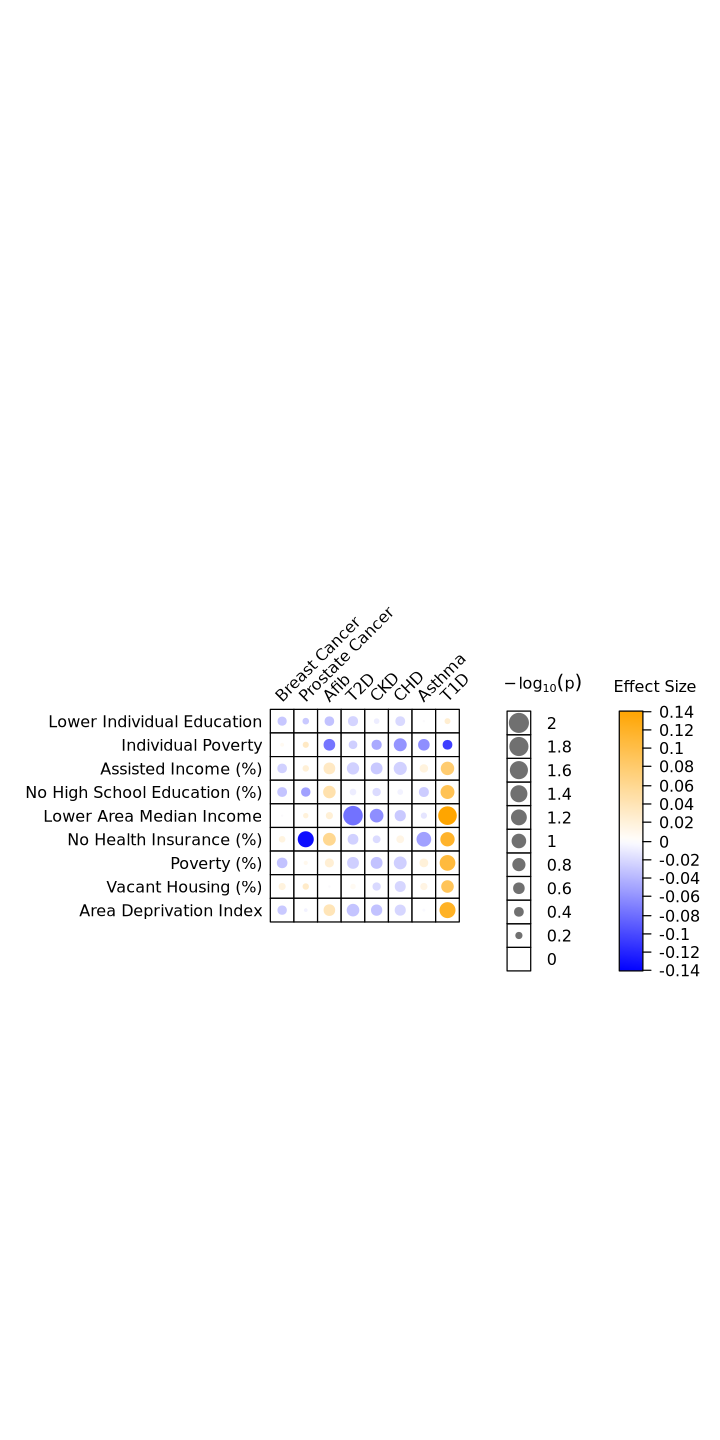

In [58]:
options(repr.plot.width = 6, repr.plot.height = 12)  # Set width and height

grid.newpage()
grid.draw(tree)

In [59]:
auc_plot_data %>%
  mutate(
    bonf_thresh = 0.05 / (n_distinct(Disease) * n_distinct(Domain)),
    size_val = ifelse(p.value > bonf_thresh, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

auc_plot_data %>%
  mutate(
    size_val = ifelse(p.adjust(p.value, method = "BH") > 0.05, 0, p.value)
  ) %>%
  select(Disease, Domain, size_val) %>%
  pivot_wider(names_from = Disease, values_from = size_val) %>%
  column_to_rownames("Domain") %>%
  as.matrix()

,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0,0,0,0,0,0,0,0
Lower Individual Education,0,0,0,0,0,0,0,0
Assisted Income (%),0,0,0,0,0,0,0,0
No High School Education (%),0,0,0,0,0,0,0,0
Lower Area Median Income,0,0,0,0,0,0,0,0
No Health Insurance (%),0,0,0,0,0,0,0,0
Poverty (%),0,0,0,0,0,0,0,0
Vacant Housing (%),0,0,0,0,0,0,0,0
Area Deprivation Index,0,0,0,0,0,0,0,0


,Asthma,Afib,Breast Cancer,CKD,CHD,Prostate Cancer,T2D,T1D
Individual Poverty,0,0,0,0,0,0,0,0
Lower Individual Education,0,0,0,0,0,0,0,0
Assisted Income (%),0,0,0,0,0,0,0,0
No High School Education (%),0,0,0,0,0,0,0,0
Lower Area Median Income,0,0,0,0,0,0,0,0
No Health Insurance (%),0,0,0,0,0,0,0,0
Poverty (%),0,0,0,0,0,0,0,0
Vacant Housing (%),0,0,0,0,0,0,0,0
Area Deprivation Index,0,0,0,0,0,0,0,0
